In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
import scipy.linalg as la

In [ ]:
# -- Definition of constants --
b = 4.0

In [ ]:
# -- Definition of functions for Matrix Method --

def basis_func(n, x):
    """_summary_

    Args:
        n (_type_): _description_
        x (_type_): _description_

    Returns:
        _type_: _description_
    """
    return np.sqrt(2.0/b) * np.sin(n * np.pi * x / b)

def Hmn(V, Nmax, b, dim='1D', m_quant=0):
    """_summary_

    Args:
        V (_type_): _description_
        Nmax (_type_): _description_
        b (_type_): _description_
        dim (str, optional): _description_. Defaults to '1D'.
        m_quant (int, optional): _description_. Defaults to 0.

    Returns:
        _type_: _description_
    """
    H = np.zeros((Nmax, Nmax))
    
    # First the elements in the diagonal
    E_0 = [(n**2 * np.pi**2) / (2.0 * b**2) for n in range(1, Nmax + 1)]
    
    # Populate the diagonal elements in the matrix
    for i in range(Nmax):
        H[i,i] = E_0[i]
        
    def Veff(x):
        if dim =='1D':
            return V(x)
        elif dim =='2D_radial':
            if x <= 1e-12:
                return V(x)
            centrifugal_term = (m_quant**2 - 0.25) / (2.0 * x**2)
            return V(x) + centrifugal_term
    
    # Now we will compute the other matrix elements by using nested loops and
    # numerical integration. 
    for n in range(Nmax):
        n_index = n + 1
        for m in range(Nmax): 
            m_index = m + 1
            integrand = lambda x: basis_func(n_index, x) * Veff(x) * basis_func(m_index, x)
            V_nm, _ = quad(integrand, 0.0, b, limit=100)
            H[n, m] += V_nm
    return H

def reconstruct_wavefunction(V, b, Nmax, dim, m_quant=0):
    """_summary_

    Args:
        Cn (_type_): _description_
        b (_type_): _description_
        Nmax (_type_): _description_

    Returns:
        _type_: _description_
    """
    energies, vectors = la.eigh(Hmn(V, Nmax=Nmax, b=b, dim=dim, m_quant=m_quant))
    
    
    
    x_grid = np.linspace(0, b, 1000)
    n_indices = np.arange(1, Nmax + 1)
    Phi = np.sqrt(2.0 / b) * np.sin(np.outer(x_grid, n_indices * np.pi / b))
    Psi = Phi @ vectors
    return Psi

In [3]:
b = 4.0
V0 = 50.0

def single_well(x):
    return 0.0 if abs(x - b/2.0) <= 0.5 else V0

# Build 1D Hamiltonian
H_1D = Hmn(single_well, Nmax=50, b=b, dim='1D')

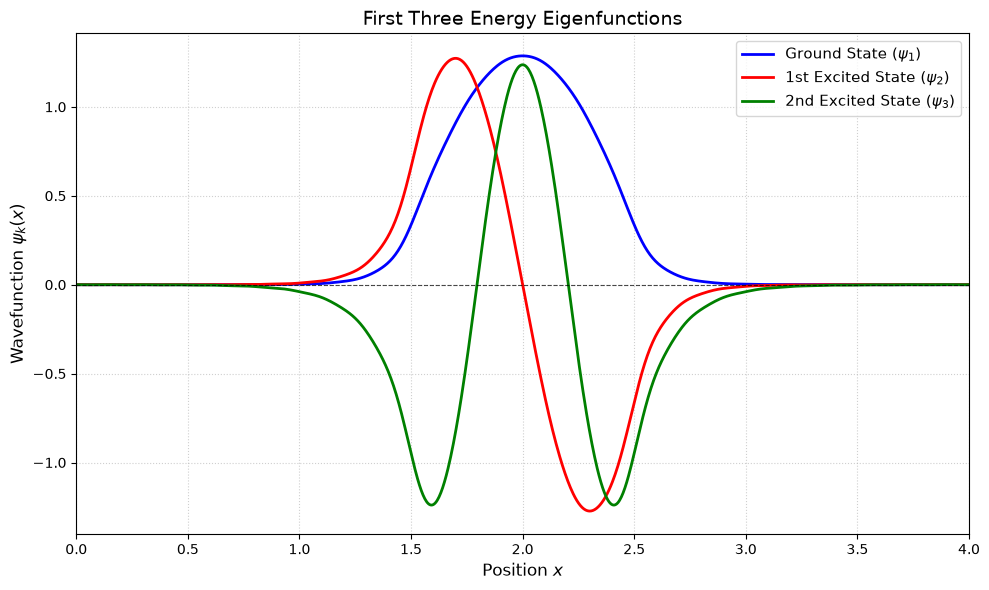

In [54]:
x_grid = np.linspace(0, 4, 1000)

psi_1 = reconstruct_wavefunction(vectors[:, 0], 4, 50)
psi_2 = reconstruct_wavefunction(vectors[:, 1], 4, 50)
psi_3 = reconstruct_wavefunction(vectors[:, 2], 4, 50)

# 3. Create the plot
plt.figure(figsize=(10, 6))

plt.plot(x_grid, psi_1, label=r'Ground State ($\psi_1$)', color='blue', linewidth=2)
plt.plot(x_grid, psi_2, label=r'1st Excited State ($\psi_2$)', color='red', linewidth=2)
plt.plot(x_grid, psi_3, label=r'2nd Excited State ($\psi_3$)', color='green', linewidth=2)

# Reference horizontal axis and styling
plt.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
plt.title("First Three Energy Eigenfunctions", fontsize=14)
plt.xlabel("Position $x$", fontsize=12)
plt.ylabel(r"Wavefunction $\psi_k(x)$", fontsize=12)
plt.xlim(0, b)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()